# Baseline рекомендательной системы семейного питания

На данном этапе история конкретной семьи не используется. Baseline нужен как точка сравнения для следующей версии, которая будет учитывать историю рецептов.

## Данные

Используем датасет [Food.com Recipes and User Interactions](https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions):

- `RAW_recipes.csv` - рецепты;
- `RAW_interactions.csv` - оценки и взаимодействия пользователей.

**Важно:** оценки пользователей не доказывают, что рецепт действительно был приготовлен. В этом проекте они служат приближенным сигналом интереса к рецепту.

## 1. Импорт библиотек и загрузка данных

In [1]:
import pandas as pd
import numpy as np
import ast
from pathlib import Path
from scipy import sparse
from scipy.stats import wilcoxon
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer

DATA_DIR = Path("/content")

RECIPES_PATH = DATA_DIR / "RAW_recipes.csv"
INTERACTIONS_PATH = DATA_DIR / "RAW_interactions.csv"

if not RECIPES_PATH.exists() or not INTERACTIONS_PATH.exists():
    raise FileNotFoundError(
        "Не найдены RAW_recipes.csv и/или RAW_interactions.csv. "
        "Проверьте имена файлов и DATA_DIR."
    )

recipes = pd.read_csv(RECIPES_PATH)
interactions = pd.read_csv(INTERACTIONS_PATH)

print("Количество рецептов:", len(recipes))
print("Количество взаимодействий:", len(interactions))

print(recipes.head())
print(interactions.head())

Количество рецептов: 231637
Количество взаимодействий: 1132367
                                         name      id  minutes  \
0  arriba   baked winter squash mexican style  137739       55   
1            a bit different  breakfast pizza   31490       30   
2                   all in the kitchen  chili  112140      130   
3                          alouette  potatoes   59389       45   
4          amish  tomato ketchup  for canning   44061      190   

   contributor_id   submitted  \
0           47892  2005-09-16   
1           26278  2002-06-17   
2          196586  2005-02-25   
3           68585  2003-04-14   
4           41706  2002-10-25   

                                                tags  \
0  ['60-minutes-or-less', 'time-to-make', 'course...   
1  ['30-minutes-or-less', 'time-to-make', 'course...   
2  ['time-to-make', 'course', 'preparation', 'mai...   
3  ['60-minutes-or-less', 'time-to-make', 'course...   
4  ['weeknight', 'time-to-make', 'course', 'main-...   

    

## 2. Предобработка

Приведем дату к `datetime`. Строки с некорректными значениями в ключевых полях удалим.

In [2]:
interactions["date"] = pd.to_datetime(interactions["date"], errors="coerce")

recipes = recipes.dropna(subset=["name"]).copy()
interactions = interactions[interactions["rating"].between(1, 5)].copy()

print("Рецептов после очистки:", len(recipes))
print("Оценок после очистки:", len(interactions))
print("Период оценок:", interactions["date"].min(), "—", interactions["date"].max())

Рецептов после очистки: 231636
Оценок после очистки: 1071520
Период оценок: 2000-01-25 00:00:00 — 2018-12-20 00:00:00


### Преобразование ингредиентов


In [3]:
def parse_ingredients(value):
    if isinstance(value, list):
        return [str(x).lower().strip() for x in value]
    if not isinstance(value, str):
        return []
    parsed = ast.literal_eval(value)
    if isinstance(parsed, list):
        return [str(x).lower().strip() for x in parsed]
    return [value.lower().strip()]


recipes["ingredients_list"] = recipes["ingredients"].apply(parse_ingredients)
recipes[["name", "ingredients", "ingredients_list"]].head()

,name,ingredients,ingredients_list
0,arriba baked winter squash mexican style,"['winter squash', 'mexican seasoning', 'mixed ...","[winter squash, mexican seasoning, mixed spice..."
1,a bit different breakfast pizza,"['prepared pizza crust', 'sausage patty', 'egg...","[prepared pizza crust, sausage patty, eggs, mi..."
2,all in the kitchen chili,"['ground beef', 'yellow onions', 'diced tomato...","[ground beef, yellow onions, diced tomatoes, t..."
3,alouette potatoes,"['spreadable cheese with garlic and herbs', 'n...","[spreadable cheese with garlic and herbs, new ..."
4,amish tomato ketchup for canning,"['tomato juice', 'apple cider vinegar', 'sugar...","[tomato juice, apple cider vinegar, sugar, sal..."


## 3. Разделение взаимодействий по времени

Используем временное разделение:

- первые 80% наблюдений по времени - `train`;
- следующие 10% - `validation`;
- последние 10% - `test`.

Рейтинг популярности будет рассчитан только по train, чтобы не использовать будущие оценки при построении рекомендаций.

Это глобальное разделение по времени. Для более строгой оценки персональных рекомендаций стоит сделать отдельное временное разделение для каждого пользователя.

In [4]:
interactions = interactions.sort_values("date").reset_index(drop=True)

train_end = interactions["date"].quantile(0.80)
val_end = interactions["date"].quantile(0.90)

train = interactions[interactions["date"] <= train_end].copy()
val = interactions[(interactions["date"] > train_end) & (interactions["date"] <= val_end)].copy()
test = interactions[interactions["date"] > val_end].copy()

print(f"Train: {len(train):,} ({len(train) / len(interactions):.1%})")
print(f"Validation: {len(val):,} ({len(val) / len(interactions):.1%})")
print(f"Test: {len(test):,} ({len(test) / len(interactions):.1%})")
print("Период train:", train["date"].min(), "-", train["date"].max())
print("Период validation:", val["date"].min(), "-", val["date"].max())
print("Период test:", test["date"].min(), "-", test["date"].max())

Train: 857,354 (80.0%)
Validation: 107,091 (10.0%)
Test: 107,075 (10.0%)
Период train: 2000-01-25 00:00:00 - 2011-09-19 00:00:00
Период validation: 2011-09-20 00:00:00 - 2013-10-24 00:00:00
Период test: 2013-10-25 00:00:00 - 2018-12-20 00:00:00


## 4. Расчет популярности рецептов

Простое среднее может переоценивать рецепты с очень малым числом оценок, поэтому используем сглаженный рейтинг.

In [5]:
recipe_stats = train.groupby("recipe_id")["rating"].agg(mean_rating="mean", rating_count="count").reset_index()

global_mean = train["rating"].mean()
min_votes = 20

recipe_stats["score"] = (
    recipe_stats["rating_count"] / (recipe_stats["rating_count"] + min_votes) * recipe_stats["mean_rating"] +
    min_votes / (recipe_stats["rating_count"] + min_votes) * global_mean
)

recipe_stats = recipe_stats.sort_values("score", ascending=False)
recipe_stats.head(10)

,recipe_id,mean_rating,rating_count,score
25086,46262,4.972603,146,4.936546
60761,107786,4.960199,201,4.934238
3660,9954,4.969697,132,4.930702
43709,78579,4.957219,187,4.929791
23283,42976,4.971963,107,4.924934
12725,25094,4.987179,78,4.923129
43112,77497,4.987179,78,4.923129
37294,66947,4.977528,89,4.921713
63073,111777,4.952703,148,4.919444
15824,30358,4.947020,151,4.915010


## 5. Профиль семьи и фильтрация рецептов

In [6]:
family_preferences = {"excluded_ingredients": ["peanut", "shrimp"]}

In [7]:
def filter_recipes(recipes, excluded_ingredients):
    excluded = [str(x).lower().strip() for x in excluded_ingredients]

    def is_allowed(ingredients):
        for ingredient in ingredients:
            for forbidden in excluded:
                if forbidden and forbidden in ingredient:
                    return False
        return True

    mask = recipes["ingredients_list"].apply(is_allowed)
    return recipes[mask].copy()


filtered_recipes = filter_recipes(recipes, family_preferences["excluded_ingredients"])
print("Рецептов до фильтрации:", len(recipes))
print("Рецептов после фильтрации:", len(filtered_recipes))

Рецептов до фильтрации: 231636
Рецептов после фильтрации: 219520


## 6. Функция baseline-рекомендаций

Функция выполняет три шага:

1. Убирает рецепты, не подходящие по ограничениям.
2. Присоединяет сглаженный рейтинг, рассчитанный на train.
3. Сортирует оставшиеся рецепты и возвращает первые `k`.

In [8]:
def recommend_baseline(recipes, recipe_stats, excluded_ingredients, k=10):
    candidates = filter_recipes(recipes, excluded_ingredients)
    candidates = candidates.merge(
        recipe_stats[["recipe_id", "score", "rating_count", "mean_rating"]],
        left_on="id", right_on="recipe_id", how="inner"
    )
    candidates = candidates.sort_values(["score", "rating_count"], ascending=[False, False])
    columns = ["id", "name", "ingredients_list",
               "score", "mean_rating", "rating_count"]
    return candidates[columns].head(k).reset_index(drop=True)


baseline_recommendations = recommend_baseline(recipes, recipe_stats, family_preferences["excluded_ingredients"])
baseline_recommendations

,id,name,ingredients_list,score,mean_rating,rating_count
0,46262,uncle bill s method for cooking turkey,"[whole turkey, salt, pepper, garlic powder, wa...",4.936546,4.972603,146
1,107786,beth s melt in your mouth barbecue ribs oven,"[pork ribs, light brown sugar, hickory smoke s...",4.934238,4.960199,201
2,9954,good eats roast turkey,"[turkey, kosher salt, light brown sugar, veget...",4.930702,4.969697,132
3,78579,pan release professional pan coating better ...,"[corn oil, vegetable shortening, all-purpose f...",4.929791,4.957219,187
4,42976,brown sugar bundt cake,"[yellow cake mix, instant vanilla flavor puddi...",4.924934,4.971963,107
5,77497,2 handed kitchen sink tomato sandwich,"[tomatoes, bread, salt and pepper, mayonnaise]",4.923129,4.987179,78
6,25094,my chicken parmigiana,"[boneless skinless chicken breast halves, egg,...",4.923129,4.987179,78
7,66947,refreshing mojito by the pitcher mojitos,"[limes, of fresh mint, sugar, white rum, club ...",4.921713,4.977528,89
8,111777,chicken pot pie with 2 crusts,"[margarine, flour, onion, salt, pepper, chicke...",4.919444,4.952703,148
9,30358,perfect pasta with no watching and no sweating,"[pasta, water]",4.915010,4.947020,151


# 8. Экспериментальная проверка H1–H3

- один каталог кандидатов для всех моделей;
- рецепты, уже оцененные пользователем в train, исключаются из рекомендаций;
- все модели сравниваются на одной тестовой выборке;
- веса Hybrid и лучшая отдельная модель выбираются только на validation;
- основная метрика - NDCG@10; K=5 и K=20 - дополнительный анализ чувствительности.


In [9]:
PRIMARY_K = 10
K_VALUES = [5, 10, 20]
SEED = 42
rng = np.random.default_rng(SEED)

catalog_ids = sorted(set(filtered_recipes["id"].astype(int)) & set(train["recipe_id"].astype(int)))
catalog = filtered_recipes[filtered_recipes["id"].isin(catalog_ids)].drop_duplicates("id").set_index("id").loc[catalog_ids].reset_index()
catalog_ids_set = set(catalog_ids)

train_model = train[train["recipe_id"].isin(catalog_ids)].copy()
val_model = val[val["recipe_id"].isin(catalog_ids)].copy()
test_model = test[test["recipe_id"].isin(catalog_ids)].copy()

train_seen = train_model.groupby("user_id")["recipe_id"].apply(set).to_dict()
pop_map = dict(zip(recipe_stats["recipe_id"], recipe_stats["score"]))
pop_map = {rid: float(pop_map[rid]) for rid in catalog_ids if rid in pop_map}

print("Каталог кандидатов:", len(catalog_ids))
print("Train / validation / test:", len(train_model), len(val_model), len(test_model))


Каталог кандидатов: 188690
Train / validation / test: 815355 74454 83001


## 8.1. User-based Collaborative Filtering

Матрица user-item строится только по `train`. Для ограничения вычислительной стоимости оставляем наиболее активных пользователей. Все три гипотезы будут оцениваться на общей тестовой выборке пользователей, вошедших в эту матрицу.

In [10]:
MIN_USER_RATINGS = 5
MAX_CF_USERS = 5000
N_NEIGHBORS = 30

user_counts = train_model.groupby("user_id").size()
active_users = user_counts[user_counts >= MIN_USER_RATINGS].sort_values(ascending=False)
cf_user_ids = active_users.head(MAX_CF_USERS).index.tolist()

cf_train = train_model[train_model["user_id"].isin(cf_user_ids)].copy()
user_to_idx = {u: i for i, u in enumerate(cf_user_ids)}
item_to_idx = {r: i for i, r in enumerate(catalog_ids)}

rows = cf_train["user_id"].map(user_to_idx).to_numpy()
cols = cf_train["recipe_id"].map(item_to_idx).to_numpy()
vals = cf_train["rating"].astype(float).to_numpy()

user_item = sparse.csr_matrix((vals, (rows, cols)), shape=(len(cf_user_ids), len(catalog_ids)), dtype=np.float32)

knn = NearestNeighbors(n_neighbors=min(N_NEIGHBORS + 1, len(cf_user_ids)), metric="cosine", algorithm="brute", n_jobs=-1)
knn.fit(user_item)

def user_cf_scores(user_id):
    if user_id not in user_to_idx:
        return {}
    uidx = user_to_idx[user_id]
    distances, indices = knn.kneighbors(user_item[uidx], return_distance=True)
    neighbor_idx = indices.ravel()
    similarities = 1.0 - distances.ravel()

    keep = (neighbor_idx != uidx) & (similarities > 0)
    neighbor_idx = neighbor_idx[keep]
    similarities = similarities[keep]
    if len(neighbor_idx) == 0:
        return {}

    neighbor_ratings = user_item[neighbor_idx]
    weighted_sum = np.asarray(
        neighbor_ratings.multiply(similarities[:, None]).sum(axis=0)
    ).ravel()
    weighted_count = np.asarray(
        (neighbor_ratings != 0).multiply(similarities[:, None]).sum(axis=0)
    ).ravel()

    scores = np.full(len(catalog_ids), np.nan, dtype=float)
    valid = weighted_count > 0
    scores[valid] = weighted_sum[valid] / weighted_count[valid]

    scores[user_item[uidx].indices] = np.nan
    return {
        catalog_ids[j]: float(scores[j])
        for j in np.where(np.isfinite(scores))[0]
    }

print("User-CF matrix:", user_item.shape)
print("Ненулевых элементов:", user_item.nnz)

User-CF matrix: (5000, 188690)
Ненулевых элементов: 556075


## 8.2. Content-Based: без ингредиентов и с ингредиентами

Обе модели строят профиль пользователя из одной и той же истории оценок. Базовые признаки: название, теги рецепта. Во второй версии дополнительно добавляется поле `ingredients`.

In [11]:
def list_to_text(value):
    if isinstance(value, list):
        return " ".join(map(str, value))
    if pd.isna(value):
        return ""
    text = str(value)
    parsed = ast.literal_eval(text)
    if isinstance(parsed, (list, tuple)):
        return " ".join(map(str, parsed))
    return text

base_parts = []
for col in ["name", "tags"]:
    if col in catalog.columns:
        base_parts.append(catalog[col].fillna("").astype(str))

base_text = pd.Series([" ".join(x) for x in zip(*base_parts)], index=catalog.index)
ingredient_text = catalog["ingredients_list"].apply(list_to_text)

text_no_ing = base_text.str.lower().tolist()
text_with_ing = (base_text + " " + ingredient_text).str.lower().tolist()

vectorizer_no_ing = TfidfVectorizer(max_features=50000, min_df=2, ngram_range=(1, 2), stop_words="english")
vectorizer_with_ing = TfidfVectorizer(max_features=70000, min_df=2, ngram_range=(1, 2), stop_words="english")

X_no_ing = vectorizer_no_ing.fit_transform(text_no_ing)
X_with_ing = vectorizer_with_ing.fit_transform(text_with_ing)
item_row = {rid: i for i, rid in enumerate(catalog_ids)}

def content_scores(user_id, X):
    hist = train_model[train_model["user_id"] == user_id]
    hist = hist[hist["recipe_id"].isin(item_row)]
    if hist.empty:
        return {}

    idx = hist["recipe_id"].map(item_row).to_numpy()
    weights = hist["rating"].to_numpy(dtype=float) - 3.0

    profile = np.asarray(X[idx].multiply(weights[:, None]).sum(axis=0)).ravel()

    if np.linalg.norm(profile) == 0:
        positive = hist[hist["rating"] >= 4]
        if positive.empty:
            return {}
        idx = positive["recipe_id"].map(item_row).to_numpy()
        profile = np.asarray(X[idx].mean(axis=0)).ravel()

    scores = np.asarray(X @ profile).ravel()

    seen = train_seen.get(user_id, set())
    return {
        catalog_ids[j]: float(scores[j])
        for j in range(len(catalog_ids))
        if catalog_ids[j] not in seen
    }

print("TF-IDF без ингредиентов:", X_no_ing.shape)
print("TF-IDF с ингредиентами:", X_with_ing.shape)

TF-IDF без ингредиентов: (188690, 50000)
TF-IDF с ингредиентами: (188690, 70000)


## 8.3. Метрики

Релевантными считаются рецепты с оценкой 4-5. Рецепты, уже оцененные пользователем в train, исключаются как из рекомендаций, так и из списка релевантных test.

In [12]:
def relevant_by_user(frame):
    raw = frame[frame["rating"] >= 4].groupby("user_id")["recipe_id"].apply(set).to_dict()
    result = {}
    for uid, ids in raw.items():
        available = (set(ids) & catalog_ids_set) - train_seen.get(uid, set())
        if available:
            result[uid] = available
    return result

val_relevant = relevant_by_user(val_model)
test_relevant = relevant_by_user(test_model)

def metrics_at_k(ranked_ids, relevant_ids, k):
    relevant_ids = set(relevant_ids)
    top = list(ranked_ids[:k])
    hits = sum(item in relevant_ids for item in top)

    precision = hits / k
    recall = hits / len(relevant_ids) if relevant_ids else np.nan

    dcg = sum((1.0 if item in relevant_ids else 0.0) / np.log2(pos + 2) for pos, item in enumerate(top))
    ideal_n = min(len(relevant_ids), k)
    idcg = sum(1.0 / np.log2(pos + 2) for pos in range(ideal_n))
    ndcg = dcg / idcg if idcg > 0 else np.nan
    return precision, recall, ndcg

def rank_scores(scores, user_id, k=PRIMARY_K):
    seen = train_seen.get(user_id, set())
    pairs = [(rid, score) for rid, score in scores.items() if rid not in seen and rid in catalog_ids_set and np.isfinite(score)]
    pairs.sort(key=lambda x: x[1], reverse=True)
    return [rid for rid, _ in pairs[:k]]

def rank_pop(user_id, k=PRIMARY_K):
    return rank_scores(pop_map, user_id, k)

def rank_cf(user_id, k=PRIMARY_K):
    return rank_scores(user_cf_scores(user_id), user_id, k)

def rank_cbf_no(user_id, k=PRIMARY_K):
    return rank_scores(content_scores(user_id, X_no_ing), user_id, k)

def rank_cbf_yes(user_id, k=PRIMARY_K):
    return rank_scores(content_scores(user_id, X_with_ing), user_id, k)

def evaluate(users, relevance, ranker, k=PRIMARY_K):
    rows = []
    for uid in users:
        rel = relevance.get(uid, set())
        if not rel:
            continue
        ranked = ranker(uid, k=k)
        p, r, n = metrics_at_k(ranked, rel, k)
        rows.append({
            "user_id": uid, "precision": p, "recall": r, "ndcg": n,
            "n_relevant": len(rel), "n_recommended": len(ranked)
        })
    return pd.DataFrame(rows)


eval_users = sorted(uid for uid, rel in test_relevant.items() if uid in user_to_idx and len(rel) > 0)
val_users = sorted(uid for uid, rel in val_relevant.items() if uid in user_to_idx and len(rel) > 0)
print("Test:", len(eval_users))
print("Validation:", len(val_users))
print("Пользователей в CF-матрице:", len(user_to_idx))


Test: 1353
Validation: 2275
Пользователей в CF-матрице: 5000


## 8.4. H1 - Popularity Baseline vs User-CF

In [13]:
h1_pop = evaluate(eval_users, test_relevant, rank_pop, k=PRIMARY_K)
h1_cf = evaluate(eval_users, test_relevant, rank_cf, k=PRIMARY_K)

h1_table = pd.DataFrame({
    "Модель": ["Popularity Baseline", "User-CF"],
    "Precision@10": [h1_pop["precision"].mean(), h1_cf["precision"].mean()],
    "Recall@10": [h1_pop["recall"].mean(), h1_cf["recall"].mean()],
    "NDCG@10": [h1_pop["ndcg"].mean(), h1_cf["ndcg"].mean()],
})
h1_table

,Модель,Precision@10,Recall@10,NDCG@10
0,Popularity Baseline,0.00170,0.005221,0.004307
1,User-CF,0.00133,0.002609,0.001916


## 8.5. H2 - Content-Based без ингредиентов vs с ингредиентами

In [14]:
h2_no = evaluate(eval_users, test_relevant, rank_cbf_no, k=PRIMARY_K)
h2_yes = evaluate(eval_users, test_relevant, rank_cbf_yes, k=PRIMARY_K)

h2_table = pd.DataFrame({
    "Модель": ["Content-Based без ингредиентов", "Content-Based с ингредиентами"],
    "Precision@10": [h2_no["precision"].mean(), h2_yes["precision"].mean()],
    "Recall@10": [h2_no["recall"].mean(), h2_yes["recall"].mean()],
    "NDCG@10": [h2_no["ndcg"].mean(), h2_yes["ndcg"].mean()],
})
h2_table

,Модель,Precision@10,Recall@10,NDCG@10
0,Content-Based без ингредиентов,0.000222,0.000166,0.000229
1,Content-Based с ингредиентами,0.000222,0.000852,0.000484


## 8.6. H3 - Hybrid vs лучшая отдельная модель

Hybrid объединяет популярность, User-CF и Content-Based с ингредиентами, веса подбираются на validation по NDCG@10.

In [15]:
def percentile_map(scores):
    if not scores:
        return {}
    return pd.Series(scores, dtype=float).dropna().rank(pct=True).to_dict()

def scores_to_array(score_map):
    arr = np.full(len(catalog_ids), np.nan, dtype=np.float32)
    for rid, value in score_map.items():
        j = item_to_idx.get(rid)
        if j is not None and np.isfinite(value):
            arr[j] = value
    return arr

pop_percentile = scores_to_array(percentile_map(pop_map))
needed_users = sorted(set(val_users) | set(eval_users))
component_cache = {}

for n, uid in enumerate(needed_users, start=1):
    component_cache[uid] = {
        "pop": pop_percentile,
        "cf": scores_to_array(percentile_map(user_cf_scores(uid))),
        "cbf": scores_to_array(percentile_map(content_scores(uid, X_with_ing))),
    }

seen_masks = {}
for uid in needed_users:
    mask = np.zeros(len(catalog_ids), dtype=bool)
    seen_idx = [item_to_idx[r] for r in train_seen.get(uid, set()) if r in item_to_idx]
    mask[seen_idx] = True
    seen_masks[uid] = mask

def cached_rank(uid, weights, k=PRIMARY_K):
    wp, wcf, wcbf = weights
    parts = component_cache[uid]
    numerator = np.zeros(len(catalog_ids), dtype=np.float32)
    denominator = np.zeros(len(catalog_ids), dtype=np.float32)

    for weight, key in ((wp, "pop"), (wcf, "cf"), (wcbf, "cbf")):
        if weight <= 0:
            continue
        values = parts[key]
        valid = np.isfinite(values)
        numerator[valid] += weight * values[valid]
        denominator[valid] += weight

    valid = (denominator > 0) & (~seen_masks[uid])
    if not np.any(valid):
        return []
    scores = np.full(len(catalog_ids), -np.inf, dtype=np.float32)
    scores[valid] = numerator[valid] / denominator[valid]
    order = np.argsort(-scores, kind="stable")[:k]
    return [catalog_ids[j] for j in order if np.isfinite(scores[j])]

def evaluate_cached(users, relevance, weights, k=PRIMARY_K):
    rows = []
    for uid in users:
        rel = relevance.get(uid, set())
        if not rel:
            continue
        ranked = cached_rank(uid, weights, k=k)
        p, r, n = metrics_at_k(ranked, rel, k)
        rows.append({
            "user_id": uid, "precision": p, "recall": r, "ndcg": n,
            "n_relevant": len(rel), "n_recommended": len(ranked)
        })
    return pd.DataFrame(rows)

weight_grid = []
for wp in [0, .25, .5, .75, 1]:
    for wcf in [0, .25, .5, .75, 1]:
        wcbf = round(1 - wp - wcf, 2)
        if wcbf >= 0:
            weight_grid.append((wp, wcf, wcbf))

weight_rows = []
for weights in weight_grid:
    val_eval = evaluate_cached(val_users, val_relevant, weights, k=PRIMARY_K)
    weight_rows.append({
        "weights": weights,
        "validation_NDCG@10": val_eval["ndcg"].mean() if not val_eval.empty else np.nan
    })

weight_df = pd.DataFrame(weight_rows).dropna().sort_values("validation_NDCG@10", ascending=False)
print(weight_df.head())
if weight_df.empty:
    raise ValueError("Не удалось подобрать веса Hybrid: проверьте validation-когорту.")

BEST_WEIGHTS = tuple(weight_df.iloc[0]["weights"])
print("Лучшие веса (Popularity, User-CF, CBF):", BEST_WEIGHTS)

standalone_weights = {
    "Popularity": (1.0, 0.0, 0.0),
    "User-CF": (0.0, 1.0, 0.0),
    "Content-Based с ингредиентами": (0.0, 0.0, 1.0),
}
standalone_val = {}
for name, weights in standalone_weights.items():
    val_eval = evaluate_cached(val_users, val_relevant, weights, k=PRIMARY_K)
    standalone_val[name] = val_eval["ndcg"].mean() if not val_eval.empty else np.nan

best_name = max(standalone_val, key=lambda name: standalone_val[name] if np.isfinite(standalone_val[name]) else -np.inf)
best_weights = standalone_weights[best_name]
print("Лучшая отдельная модель по validation:", best_name)

h3_best = evaluate_cached(eval_users, test_relevant, best_weights, k=PRIMARY_K)
h3_hybrid = evaluate_cached(eval_users, test_relevant, BEST_WEIGHTS, k=PRIMARY_K)

print(pd.DataFrame({
    "Модель": [f"Лучшая отдельная: {best_name}", "Hybrid"],
    "Precision@10": [h3_best["precision"].mean(), h3_hybrid["precision"].mean()],
    "Recall@10": [h3_best["recall"].mean(), h3_hybrid["recall"].mean()],
    "NDCG@10": [h3_best["ndcg"].mean(), h3_hybrid["ndcg"].mean()],
}))


            weights  validation_NDCG@10
12  (0.75, 0, 0.25)            0.004058
4         (0, 1, 0)            0.003675
9     (0.5, 0, 0.5)            0.003647
14        (1, 0, 0)            0.003636
5   (0.25, 0, 0.75)            0.003352
Лучшие веса (Popularity, User-CF, CBF): (0.75, 0, 0.25)
Лучшая отдельная модель по validation: User-CF
                      Модель  Precision@10  Recall@10   NDCG@10
0  Лучшая отдельная: User-CF      0.001330   0.002609  0.001916
1                     Hybrid      0.001478   0.001207  0.001600


## 8.7. Статистическая проверка гипотез

Для каждой гипотезы сравниваем парные NDCG@10 на уровне пользователей. Используем односторонний критерий Уилкоксона и 95% bootstrap-интервал среднего прироста. Три p-value корректируются методом Holm.

Если p-value после поправки меньше 0.05, а средний прирост положителен, результат поддерживает соответствующую гипотезу.

In [16]:
N_BOOT = 2000
ALPHA = 0.05
stats_rng = np.random.default_rng(SEED)

def paired_stats(name, left, right):
    pair = left[["user_id", "ndcg"]].merge(right[["user_id", "ndcg"]], on="user_id", suffixes=("_left", "_right"))
    delta = pair["ndcg_right"].to_numpy(dtype=float) - pair["ndcg_left"].to_numpy(dtype=float)
    delta = delta[np.isfinite(delta)]
    if len(delta) < 2:
        return {
            "Сравнение": name, "N пользователей": len(delta),
            "Прирост NDCG@10": np.nan, "CI 2.5%": np.nan,
            "CI 97.5%": np.nan, "p-value": np.nan
        }

    boot = np.array([stats_rng.choice(delta, size=len(delta), replace=True).mean() for _ in range(N_BOOT)])
    try:
        p = 1.0 if np.allclose(delta, 0) else float(wilcoxon(delta, alternative="greater").pvalue)
    except ValueError:
        p = np.nan

    lo, hi = np.quantile(boot, [0.025, 0.975])
    return {
        "Сравнение": name, "N пользователей": len(delta),
        "Прирост NDCG@10": float(delta.mean()),
        "CI 2.5%": float(lo), "CI 97.5%": float(hi), "p-value": p
    }

tests = [
    paired_stats("H1: User-CF минус Popularity", h1_pop, h1_cf),
    paired_stats("H2: CBF+ингредиенты минус CBF без ингредиентов", h2_no, h2_yes),
    paired_stats("H3: Hybrid минус лучшая отдельная модель", h3_best, h3_hybrid),
]
stat_table = pd.DataFrame(tests)

def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    adjusted = np.full(len(p), np.nan)
    valid = np.where(np.isfinite(p))[0]
    order = valid[np.argsort(p[valid])]
    running = 0.0
    m = len(order)
    for rank, idx_ in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[idx_]))
        adjusted[idx_] = running
    return adjusted

stat_table["p-value Holm"] = holm_adjust(stat_table["p-value"].to_numpy())
stat_table["Значимо при 0.05"] = stat_table["p-value Holm"] < ALPHA
display(stat_table)


,Сравнение,N пользователей,Прирост NDCG@10,CI 2.5%,CI 97.5%,p-value,p-value Holm,Значимо при 0.05
0,H1: User-CF минус Popularity,1353,-0.002391,-0.005409,0.000220,0.894848,0.894848,False
1,H2: CBF+ингредиенты минус CBF без ингредиентов,1353,0.000254,-0.000098,0.000836,0.136661,0.409983,False
2,H3: Hybrid минус лучшая отдельная модель,1353,-0.000315,-0.001685,0.000932,0.443151,0.886302,False


## 8.8. Сравнение при K=5, 10 и 20

Основной результат - K=10. K=5 и K=20 показывают чувствительность результата к длине списка.


,K,Модель,Precision,Recall,NDCG
0,5,Popularity,0.001922,0.004284,0.003987
1,5,User-CF,0.001183,0.001722,0.001481
4,5,Лучшая отдельная (User-CF),0.001183,0.001722,0.001481
5,5,Hybrid,0.001626,0.000529,0.001425
3,5,CBF с ингредиентами,0.000148,0.000106,0.000251
2,5,CBF без ингредиентов,0.000148,0.000106,0.000158
6,10,Popularity,0.001700,0.005221,0.004307
7,10,User-CF,0.001330,0.002609,0.001916
10,10,Лучшая отдельная (User-CF),0.001330,0.002609,0.001916
11,10,Hybrid,0.001478,0.001207,0.001600


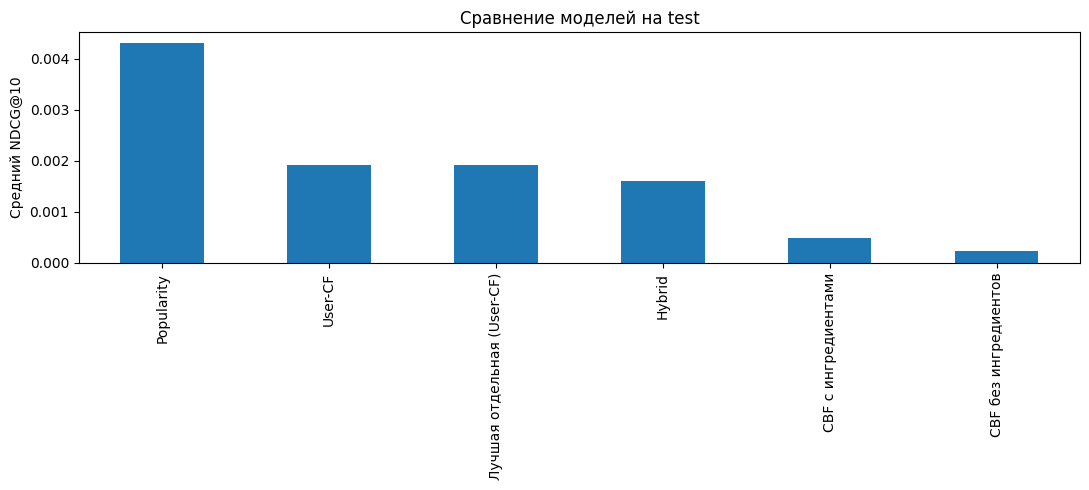

In [17]:
model_rankers = {
    "Popularity": rank_pop,
    "User-CF": rank_cf,
    "CBF без ингредиентов": rank_cbf_no,
    "CBF с ингредиентами": rank_cbf_yes,
}

multi_k_rows = []
for k in K_VALUES:
    for model_name, ranker in model_rankers.items():
        result = evaluate(eval_users, test_relevant, ranker, k)
        multi_k_rows.append({
            "K": k, "Модель": model_name,
            "Precision": result["precision"].mean(),
            "Recall": result["recall"].mean(),
            "NDCG": result["ndcg"].mean()
        })

    best_result = evaluate_cached(eval_users, test_relevant, best_weights, k)
    hybrid_result = evaluate_cached(eval_users, test_relevant, BEST_WEIGHTS, k)
    multi_k_rows.extend([
        {"K": k, "Модель": f"Лучшая отдельная ({best_name})",
         "Precision": best_result["precision"].mean(),
         "Recall": best_result["recall"].mean(),
         "NDCG": best_result["ndcg"].mean()},
        {"K": k, "Модель": "Hybrid",
         "Precision": hybrid_result["precision"].mean(),
         "Recall": hybrid_result["recall"].mean(),
         "NDCG": hybrid_result["ndcg"].mean()},
    ])

multi_k_table = pd.DataFrame(multi_k_rows)
display(multi_k_table.sort_values(["K", "NDCG"], ascending=[True, False]))

primary_results = multi_k_table[multi_k_table["K"] == PRIMARY_K].sort_values("NDCG", ascending=False)
ax = primary_results.plot(x="Модель", y="NDCG", kind="bar", figsize=(11, 5), legend=False, title="Сравнение моделей на test")
ax.set_ylabel("Средний NDCG@10")
ax.set_xlabel("")
fig = ax.get_figure()
fig.tight_layout()


## 8.9. Дополнительная оценка похожести рецептов Similarity-NDCG@10

Обычный NDCG считает релевантными только конкретные рецепты, получившие оценку 4-5, но рекомендация может быть полезной и тогда, когда она не совпала с точным `recipe_id`, а похожа по ингредиентам на понравившееся блюдо.

Добавляем дополнительную метрику:

1. Для каждого пользователя берем его положительно оценённые рецепты из test.
2. Представляем ингредиенты каждого рецепта как TF-IDF-вектор.
3. Для каждого рецепта-кандидата рассчитываем максимальное косинусное сходство с любым положительно оцененным test-рецептом этого пользователя.
4. Используем это сходство как градуированную релевантность от 0 до 1 и рассчитываем Similarity-NDCG@10.


In [18]:
ingredient_vectorizer_eval = TfidfVectorizer(lowercase=True,  token_pattern=r"(?u)\b\w+\b", min_df=1)
X_ingredients_eval = ingredient_vectorizer_eval.fit_transform(catalog["ingredients_list"].apply(list_to_text).str.lower().tolist())

def ingredient_similarity_relevance(user_id):
    liked_ids = sorted(test_relevant.get(user_id, set()))
    if not liked_ids:
        return np.zeros(len(catalog_ids), dtype=np.float32)
    liked_idx = [item_to_idx[rid] for rid in liked_ids if rid in item_to_idx]
    if not liked_idx:
        return np.zeros(len(catalog_ids), dtype=np.float32)
    similarities = X_ingredients_eval @ X_ingredients_eval[liked_idx].T
    best_similarity = np.asarray(similarities.max(axis=1).toarray()).ravel()
    best_similarity = np.nan_to_num(best_similarity, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    seen_idx = [item_to_idx[rid] for rid in train_seen.get(user_id, set()) if rid in item_to_idx]
    best_similarity[seen_idx] = 0.0
    return np.clip(best_similarity, 0.0, 1.0)


def graded_ndcg_at_k(ranked_ids, relevance_by_item, k=PRIMARY_K):
    ranked_idx = [item_to_idx[rid] for rid in ranked_ids[:k] if rid in item_to_idx]
    gains = np.power(2.0, relevance_by_item[ranked_idx]) - 1.0
    discounts = np.log2(np.arange(2, len(gains) + 2))
    dcg = float(np.sum(gains / discounts))
    ideal_relevance = np.sort(relevance_by_item)[::-1][:k]
    ideal_gains = np.power(2.0, ideal_relevance) - 1.0
    ideal_discounts = np.log2(np.arange(2, len(ideal_gains) + 2))
    idcg = float(np.sum(ideal_gains / ideal_discounts))
    return dcg / idcg if idcg > 0 else 0.0


similarity_relevance_cache = {}
for n, uid in enumerate(eval_users, start=1):
    similarity_relevance_cache[uid] = ingredient_similarity_relevance(uid)

def evaluate_similarity_ndcg(users, ranker, k=PRIMARY_K):
    rows = []
    for uid in users:
        relevance_vector = similarity_relevance_cache.get(uid)
        if relevance_vector is None:
            continue
        ranked = ranker(uid, k=k)
        score = graded_ndcg_at_k(ranked, relevance_vector, k=k)
        rows.append({"user_id": uid, "similarity_ndcg": score})
    return pd.DataFrame(rows)


similarity_rankers = {
    "Popularity": rank_pop,
    "User-CF": rank_cf,
    "CBF без ингредиентов": rank_cbf_no,
    "CBF с ингредиентами": rank_cbf_yes,
    "Лучшая отдельная модель": lambda uid, k=PRIMARY_K: cached_rank(uid, best_weights, k),
    "Hybrid": lambda uid, k=PRIMARY_K: cached_rank(uid, BEST_WEIGHTS, k),
}

similarity_rows = []
for model_name, ranker in similarity_rankers.items():
    soft_eval = evaluate_similarity_ndcg(eval_users, ranker, k=PRIMARY_K)
    similarity_rows.append({
        "Модель": model_name,
        "Similarity-NDCG@10": (soft_eval["similarity_ndcg"].mean() if not soft_eval.empty else np.nan)
    })

similarity_table = pd.DataFrame(similarity_rows).sort_values("Similarity-NDCG@10", ascending=False)
standard_ndcg = {
    "Popularity": h1_pop["ndcg"].mean(),
    "User-CF": h1_cf["ndcg"].mean(),
    "CBF без ингредиентов": h2_no["ndcg"].mean(),
    "CBF с ингредиентами": h2_yes["ndcg"].mean(),
    "Лучшая отдельная модель": h3_best["ndcg"].mean(),
    "Hybrid": h3_hybrid["ndcg"].mean(),
}
similarity_table["Обычный NDCG@10"] = similarity_table["Модель"].map(standard_ndcg)
similarity_table = similarity_table[["Модель", "Обычный NDCG@10", "Similarity-NDCG@10"]]
similarity_table


,Модель,Обычный NDCG@10,Similarity-NDCG@10
3,CBF с ингредиентами,0.000484,0.154501
5,Hybrid,0.001600,0.151803
4,Лучшая отдельная модель,0.001916,0.126377
1,User-CF,0.001916,0.126377
2,CBF без ингредиентов,0.000229,0.113135
0,Popularity,0.004307,0.105358


# 9. Ограничения

**Ограничения эксперимента:**
- Food.com содержит оценки, а не подтвержденные события выбора рецепта.
- Общая тестовая выборка ограничена пользователями, для которых доступен User-CF.
- Ингредиентные ограничения реализованы поиском подстроки и требуют более надежного парсинга в реальном продукте.
- Низкие офлайн-метрики показывают совпадение с конкретным блюдом, а не семантическую близость блюд или удовлетворенность семьи.
- Для проверки практической пользы нужен семейный пилот с обратной связью нескольких членов семьи.

# 10. Пример рекомендаций для одного пользователя

Выбираем пользователя из тестовой выборки, для него выводим:
1. несколько рецептов из train, которые пользователь оценил на 4–5;
2. Top-10 рекомендаций Hybrid;
3. релевантные рецепты из test, которые модель должна была бы предсказать.


In [19]:
history_sizes = train_model.groupby("user_id").size()
eligible = [uid for uid in eval_users if uid in history_sizes.index and len(test_relevant.get(uid, set())) > 0]
sample_user = max(eligible, key=lambda uid: history_sizes.loc[uid])
recipe_info = catalog.set_index("id")

def recipe_table(recipe_ids, ratings=None):
    rows = []
    ratings = ratings or {}
    for rid in recipe_ids:
        if rid not in recipe_info.index:
            continue
        row = recipe_info.loc[rid]
        ingredients = row.get("ingredients_list", [])
        rows.append({
            "recipe_id": rid,
            "Название": row.get("name", ""),
            "Оценка пользователя": ratings.get(rid, np.nan),
            "Ингредиенты": ", ".join(map(str, ingredients[:8])) if isinstance(ingredients, list) else str(ingredients)[:160]
        })
    return pd.DataFrame(rows)


sample_history = train_model[(train_model["user_id"] == sample_user) & (train_model["rating"] >= 4)].sort_values(["rating", "date"], ascending=[False, False])
sample_train_ids = sample_history["recipe_id"].drop_duplicates().head(7).tolist()
sample_train_ratings = sample_history.drop_duplicates("recipe_id").set_index("recipe_id")["rating"].to_dict()
sample_recommended_ids = cached_rank(sample_user, BEST_WEIGHTS, 10)
sample_test_ids = sorted(test_relevant.get(sample_user, set()),
    key=lambda rid: (test_model.loc[(test_model["user_id"] == sample_user) & (test_model["recipe_id"] == rid), "rating"].max()), reverse=True)[:10]

print(f"Пользователь: {sample_user}")
print(f"Всего взаимодействий в train: {history_sizes.loc[sample_user]}")
print(f"Положительных рецептов в train: {len(sample_history)}")

print("\nРецепты, которые пользователь высоко оценил в train:")
print(recipe_table(sample_train_ids, sample_train_ratings))

print("\nTop-10 рекомендаций Hybrid:")
print(recipe_table(sample_recommended_ids))

print("\nРецепты, которые пользователь высоко оценил в test:")
test_rating_map = test_model[(test_model["user_id"] == sample_user) & (test_model["recipe_id"].isin(sample_test_ids))].drop_duplicates("recipe_id").set_index("recipe_id")["rating"].to_dict()
print(recipe_table(sample_test_ids, test_rating_map))

Пользователь: 424680
Всего взаимодействий в train: 6380
Положительных рецептов в train: 6377

Рецепты, которые пользователь высоко оценил в train:
   recipe_id                                           Название  \
0     369515                             caribbean banana bread   
1     312176                       caramel  banana    date loaf   
2     403325  shirley corriher s chocolate chip cookies  med...   
3     324725                      low sodium chewy granola bars   
4     313114                               fruited turkey wraps   
5     437351                          beet root and apple raita   
6     462998  quinoa with apricots   pistachios  gluten free...   

   Оценка пользователя                                        Ингредиенты  
0                    5  butter, light cream cheese, sugar, egg, all-pu...  
1                    5  self raising flour, bicarbonate of soda, groun...  
2                    5  cake flour, salt, baking powder, butter, short...  
3           